In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [14]:
# Breast Cancer Classification using Neural Network

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout


In [2]:
# Load Dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [3]:
# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
# ----------------------------
# Build Neural Network
# ----------------------------
model = Sequential([
    Dense(64, activation='relu', input_shape=(30,)),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.3),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-25 08:07:17.152811: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [5]:
# Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train Model
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# Predictions
y_prob = model.predict(X_test)

y_pred = (y_prob > 0.5).astype(int)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5412 - loss: 0.6935 - val_accuracy: 0.8571 - val_loss: 0.5264
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8544 - loss: 0.4603 - val_accuracy: 0.9341 - val_loss: 0.3304
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9176 - loss: 0.3005 - val_accuracy: 0.9231 - val_loss: 0.2054
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9368 - loss: 0.2095 - val_accuracy: 0.9231 - val_loss: 0.1493
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9478 - loss: 0.1510 - val_accuracy: 0.9451 - val_loss: 0.1257
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9643 - loss: 0.1442 - val_accuracy: 0.9560 - val_loss: 0.1120
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9725 - loss: 0.0956 - val_accuracy: 0.9560 - val_loss: 0.1064
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9560 - loss: 0.1046 - val_accuracy: 0.9670 - val_loss:

In [6]:
# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

In [7]:
print("\n========== MODEL PERFORMANCE ==========")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"AUC Score : {auc:.4f}")


========== MODEL PERFORMANCE ==========
Accuracy  : 0.9825
Precision : 0.9726
Recall    : 1.0000
F1 Score  : 0.9861
AUC Score : 0.9934


In [9]:
# Classification Report
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"]
))


Classification Report:

              precision    recall  f1-score   support

   Malignant       1.00      0.95      0.98        43
      Benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



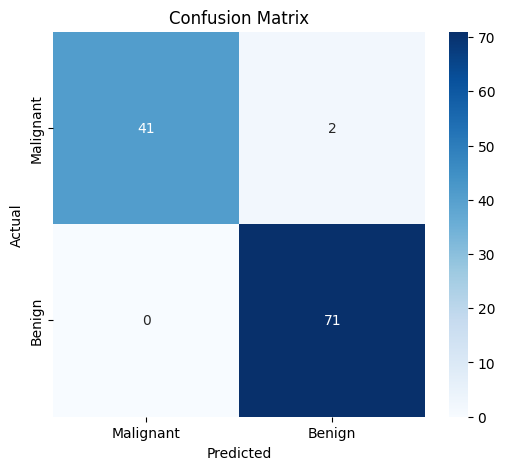

In [12]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

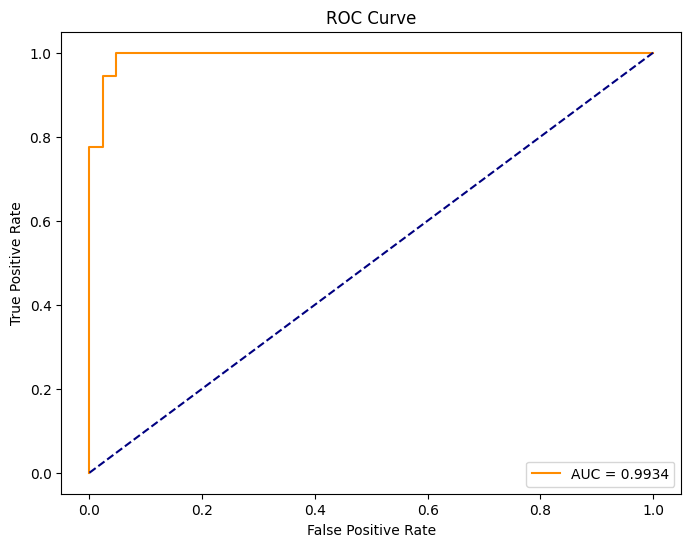

In [15]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.4f}",
    color='darkorange'
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    color='navy'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

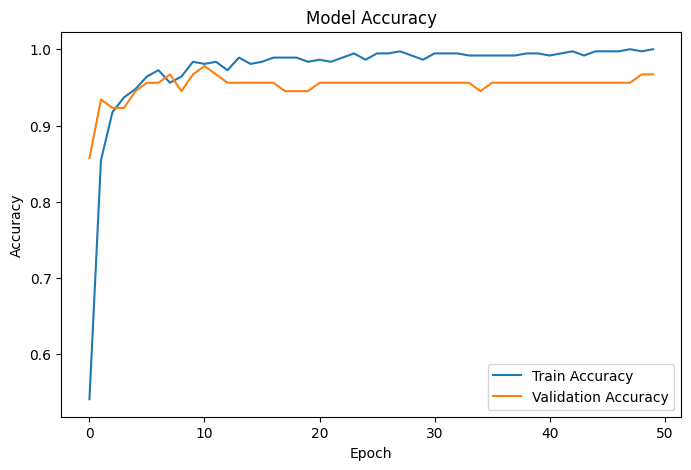

In [16]:
# Training Accuracy Plot
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

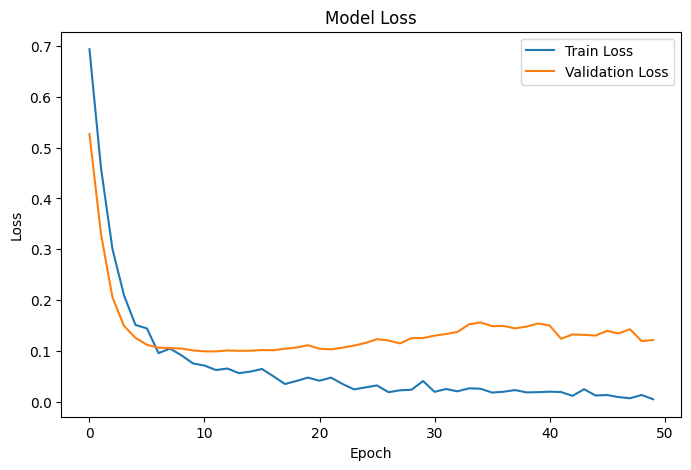

In [17]:
# Training Loss Plot
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [18]:
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# 1. Define a model building function that accepts hyperparameters (hp)
def build_model(hp):
    model = Sequential()
    
    # Tune the number of units in the first dense layer (ranging from 32 to 128)
    hp_units = hp.Int('units_1', min_value=32, max_value=128, step=32)
    model.add(Dense(units=hp_units, activation='relu', input_shape=(30,)))
    
    # Tune the dropout rate to prevent overfitting
    hp_dropout = hp.Float('dropout', min_value=0.1, max_value=0.5, step=0.1)
    model.add(Dropout(hp_dropout))
    
    # Tune the units for the second dense layer
    model.add(Dense(units=hp.Int('units_2', min_value=16, max_value=64, step=16), activation='relu'))
    
    # Output layer for binary classification
    model.add(Dense(1, activation='sigmoid'))
    
    # Tune the learning rate for the optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    
    model.compile(
        optimizer=Adam(learning_rate=hp_learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# 2. Set up the Hyperband tuner
tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=20,
    factor=3,
    directory='hyper_dir',
    project_name='breast_cancer_tuning'
)

# 3. Start the hyperparameter search
tuner.search(
    X_train, y_train,
    epochs=20,
    validation_split=0.2,
    verbose=1
)

# 4. Get the optimal hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print(f"""
Tuning Complete!
Optimal units in Layer 1: {best_hps.get('units_1')}
Optimal dropout rate: {best_hps.get('dropout')}
Optimal units in Layer 2: {best_hps.get('units_2')}
Optimal learning rate: {best_hps.get('learning_rate')}
""")

# 5. Build and train the model with the best hyperparameters found
best_model = tuner.hypermodel.build(best_hps)
history = best_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Trial 30 Complete [00h 00m 04s]
val_accuracy: 0.9780219793319702

Best val_accuracy So Far: 0.9890109896659851
Total elapsed time: 00h 01m 13s

Tuning Complete!
Optimal units in Layer 1: 96
Optimal dropout rate: 0.1
Optimal units in Layer 2: 16
Optimal learning rate: 0.01

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9176 - loss: 0.1956 - val_accuracy: 0.9451 - val_loss: 0.0994
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9808 - loss: 0.0617 - val_accuracy: 0.9780 - val_loss: 0.0749
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9890 - loss: 0.0426 - val_accuracy: 0.9670 - val_loss: 0.0722
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9863 - loss: 0.0326 - val_accuracy: 0.9560 - val_loss: 0.0924
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9863 - loss: 0.0305 - val_accuracy: 0.9780 - val_loss: 0.0791
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9835 - loss: 0.0281 - val_accura

In [19]:
# Evaluate the best model on the test set
y_prob_best = best_model.predict(X_test)
y_pred_best = (y_prob_best > 0.5).astype(int)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
auc_best = roc_auc_score(y_test, y_prob_best)

print("\n========== PERFORMANCE COMPARISON ==========")
print("Metric\t\tBefore Tuning\tAfter Tuning")
print("-" * 45)
print(f"Accuracy\t0.9825\t\t{accuracy_best:.4f}")
print(f"Precision\t0.9726\t\t{precision_best:.4f}")
print(f"Recall\t\t1.0000\t\t{recall_best:.4f}")
print(f"F1 Score\t0.9861\t\t{f1_best:.4f}")
print(f"AUC Score\t0.9934\t\t{auc_best:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

========== PERFORMANCE COMPARISON ==========
Metric		Before Tuning	After Tuning
---------------------------------------------
Accuracy	0.9825		0.9649
Precision	0.9726		0.9718
Recall		1.0000		0.9718
F1 Score	0.9861		0.9718
AUC Score	0.9934		0.9831


In [20]:
import numpy as np
from sklearn.model_selection import KFold
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# 1. Set up K-Fold Cross-Validation (5 Splits)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

fold_no = 1
acc_per_fold = []
loss_per_fold = []

for train_index, val_index in kfold.split(X):
    # Split the dataset into training and validation folds
    X_train_k, X_val_k = X[train_index], X[val_index]
    y_train_k, y_val_k = y[train_index], y[val_index]
    
    # Define the neural network architecture for the fold
    model_k = Sequential([
        Dense(64, activation='relu', input_shape=(30,)),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    model_k.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    print(f'--- Training for Fold {fold_no} ---')
    
    # Train the model silently (verbose=0 keeps output clean)
    history_k = model_k.fit(
        X_train_k, y_train_k,
        epochs=30,
        batch_size=16,
        verbose=0
    )
    
    # Evaluate the model on the current validation fold
    scores = model_k.evaluate(X_val_k, y_val_k, verbose=0)
    print(f'Score for fold {fold_no}: Loss: {scores[0]:.4f} | Accuracy: {scores[1]*100:.2f}%\n')
    
    acc_per_fold.append(scores[1] * 100)
    loss_per_fold.append(scores[0])
    
    fold_no += 1

# 2. Print average performance across all folds
print("\n========== K-FOLD CROSS-VALIDATION RESULTS ==========")
print(f'Average Accuracy: {np.mean(acc_per_fold):.2f}% (+/- {np.std(acc_per_fold):.2f}%)')
print(f'Average Loss: {np.mean(loss_per_fold):.4f}')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Training for Fold 1 ---
Score for fold 1: Loss: 0.2950 | Accuracy: 92.98%

--- Training for Fold 2 ---
Score for fold 2: Loss: 0.4050 | Accuracy: 85.09%

--- Training for Fold 3 ---
Score for fold 3: Loss: 0.4988 | Accuracy: 76.32%

--- Training for Fold 4 ---
Score for fold 4: Loss: 0.4734 | Accuracy: 79.82%

--- Training for Fold 5 ---
Score for fold 5: Loss: 0.4310 | Accuracy: 82.30%


========== K-FOLD CROSS-VALIDATION RESULTS ==========
Average Accuracy: 83.30% (+/- 5.64%)
Average Loss: 0.4207
